<a href="https://colab.research.google.com/github/dwikidias/UTS-Machine-Learning-kelompok-14/blob/main/kode/DwikiDiastoro_regresi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pembelajaran Mesin - UTS ML (Regresi)
## Task 1: Estimasi Durasi Pengiriman (P50 & P90)

Notebook ini telah dirapikan secara linear agar dapat dijalankan bersih dari awal hingga akhir (*Restart & Run All*).

In [ ]:
# 1. Setup, Import, Seed, & Path Portabel

In [ ]:
import os
import sys
import random
import numpy as np
import pandas as pd
import sklearn
import lightgbm as lgb
import shap

# 1. Reproducibility Configuration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print("=== LIBRARY VERSIONS ===")
print(f"Python     : {sys.version.split()[0]}")
print(f"NumPy      : {np.__version__}")
print(f"Pandas     : {pd.__version__}")
print(f"Scikit-Learn: {sklearn.__version__}")
print(f"LightGBM   : {lgb.__version__}")
print(f"SHAP       : {shap.__version__}")

# 2. Portable Path Resolver
DRIVE_DATA = '/content/drive/MyDrive/matkul/PEMBELAJARAN MESIN(MACHINE LEARNING) BS1TK-47-REG-G05/data_uts_ML'
DATA_DIR = os.environ.get('UTS_DATA_DIR', 'data')

if not os.path.exists(DATA_DIR):
    if os.path.exists(DRIVE_DATA):
        DATA_DIR = DRIVE_DATA
        print(f"Menggunakan data dari Google Drive: {DATA_DIR}")
    else:
        # Mencoba otomatis mount drive jika di Colab
        try:
            from google.colab import drive
            drive.mount('/content/drive')
            if os.path.exists(DRIVE_DATA):
                DATA_DIR = DRIVE_DATA
                print(f"Google Drive berhasil dimount. Path: {DATA_DIR}")
        except ImportError:
            pass

if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR, exist_ok=True)
    print(f"Folder {DATA_DIR} dibuat. Pastikan file regresi_train.csv/regresi_test.csv berada di direktori tersebut.")

def load_dataset(base_name):
    gz_path = os.path.join(DATA_DIR, f'{base_name}.csv.gz')
    csv_path = os.path.join(DATA_DIR, f'{base_name}.csv')
    if os.path.exists(gz_path):
        return pd.read_csv(gz_path)
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'File {base_name}.csv(.gz) tidak ditemukan di {DATA_DIR}')

train_df = load_dataset('regresi_train')
test_df = load_dataset('regresi_test')
print(f"\nSukses memuat dataset! Train shape: {train_df.shape} | Test shape: {test_df.shape}")

=== LIBRARY VERSIONS ===
Python     : 3.13.18
NumPy      : 2.4.6
Pandas     : 2.2.3
Scikit-Learn: 1.6.1
LightGBM   : 4.6.0
SHAP       : 0.54.1
Menggunakan data dari Google Drive: /content/drive/MyDrive/matkul/PEMBELAJARAN MESIN(MACHINE LEARNING) BS1TK-47-REG-G05/data_uts_ML

Sukses memuat dataset! Train shape: (250000, 77) | Test shape: (60000, 76)


## 2. Feature Preprocessing & Alignment
Di bawah ini didefinisikan fungsi pemrosesan fitur yang aman terhadap kebocoran (*leakage-free*) serta penyelarasan kategori agar tidak terjadi kegagalan saat menangani data baru di pengujian.

In [ ]:
# 1. Fungsi Preprocessing Aman terhadap Leakage
def prepare_features(df_in, route_medians=None, hub_medians=None, global_jarak_med=None, layanan_berat_med=None, freq_maps=None):
    d = df_in.copy()
    d['tgl_pickup'] = pd.to_datetime(d['tgl_pickup'])
    d['pickup_month'] = d['tgl_pickup'].dt.month
    d['pickup_dayofweek'] = d['tgl_pickup'].dt.dayofweek
    d['pickup_is_weekend'] = (d['pickup_dayofweek'] >= 5).astype(int)
    if 'jam_pickup' in d.columns:
        if d['jam_pickup'].dtype == 'object':
            d['jam_pickup_hour'] = pd.to_datetime(d['jam_pickup'], format='%H:%M:%S', errors='coerce').dt.hour.fillna(12)
        else:
            d['jam_pickup_hour'] = d['jam_pickup']

    # Tangani sentinel jarak_km (0 dan 9999)
    d['is_jarak_invalid'] = d['jarak_km'].isin([0, 9999]).astype(int)
    d.loc[d['jarak_km'].isin([0, 9999]), 'jarak_km'] = np.nan

    # Flag missing berat_kg
    d['is_berat_missing'] = d['berat_kg'].isna().astype(int)

    # Fit statistik imputasi hanya jika belum diberikan (training fold)
    if route_medians is None:
        route_medians = d.groupby(['kota_asal', 'kota_tujuan'])['jarak_km'].median()
        hub_medians = d.groupby(['hub_asal', 'pulau_tujuan'])['jarak_km'].median()
        global_jarak_med = d['jarak_km'].median()
        layanan_berat_med = d.groupby('layanan')['berat_kg'].median()

    # Imputasi jarak_km bertingkat
    route_vals = pd.Series(
        d.set_index(['kota_asal', 'kota_tujuan']).index.map(route_medians).to_numpy(),
        index=d.index
    )
    hub_vals = pd.Series(
        d.set_index(['hub_asal', 'pulau_tujuan']).index.map(hub_medians).to_numpy(),
        index=d.index
    )
    d['jarak_km'] = d['jarak_km'].fillna(route_vals).fillna(hub_vals).fillna(global_jarak_med)

    # Imputasi berat_kg per layanan
    d['berat_kg'] = d['berat_kg'].fillna(d['layanan'].map(layanan_berat_med)).fillna(layanan_berat_med.median())

    # Frequency encoding
    high_card_cols = ['kota_tujuan', 'kota_asal', 'mitra_kurir', 'hub_asal']
    if freq_maps is None:
        freq_maps = {col: d[col].value_counts(normalize=True).to_dict() for col in high_card_cols}
    for col in high_card_cols:
        d[f'{col}_freq'] = d[col].map(freq_maps[col]).fillna(0.0)

    return d, (route_medians, hub_medians, global_jarak_med, layanan_berat_med, freq_maps)

# 2. Fungsi Penyelarasan Kategori untuk Kategori Baru (unseen categories) ke '__UNKNOWN__'
def align_categories(tr_df, other_dfs, cat_cols):
    tr_df = tr_df.copy()
    others = [d.copy() for d in other_dfs]
    for c in cat_cols:
        known = list(tr_df[c].astype(str).unique()) + ['__UNKNOWN__']
        dtype = pd.CategoricalDtype(categories=known, ordered=False)
        tr_df[c] = tr_df[c].astype(str).astype(dtype)
        for d in others:
            s = d[c].astype(str)
            d[c] = s.where(s.isin(known), '__UNKNOWN__').astype(dtype)
    return [tr_df] + others

In [ ]:
# 1. Duplikat & Rentang Tanggal
print("=== 1. DUPLIKAT & RENTANG TANGGAL ===")
print("Duplikat id_paket (train):", train_df['id_paket'].duplicated().sum())
print("Duplikat id_paket (test) :", test_df['id_paket'].duplicated().sum())
print("Rentang tgl_pickup train :", train_df['tgl_pickup'].min(), "s/d", train_df['tgl_pickup'].max())
print("Rentang tgl_pickup test  :", test_df['tgl_pickup'].min(), "s/d", test_df['tgl_pickup'].max())

# 2. Missing Values (> 0%)
print("\n=== 2. MISSING VALUES (%) ===")
miss_tr = (train_df.isna().mean() * 100).round(2)
miss_ts = (test_df.isna().mean() * 100).round(2)
miss_df = pd.DataFrame({'train_%': miss_tr, 'test_%': miss_ts})
print(miss_df[(miss_df['train_%'] > 0) | (miss_df['test_%'] > 0)])

# 3. Audit Target (durasi_jam) & Nilai Tidak Wajar
print("\n=== 3. TARGET (durasi_jam) & ANOMALI NUMERIK ===")
print(train_df['durasi_jam'].describe(percentiles=[0.01, 0.05, 0.5, 0.9, 0.99]))
print("durasi_jam <= 0:", (train_df['durasi_jam'] <= 0).sum())

for col in ['jarak_km', 'berat_kg', 'volume_liter', 'nilai_barang', 'jumlah_scan']:
    if col in train_df.columns:
        print(f"{col:15s} | train min={train_df[col].min():.3f}, max={train_df[col].max():.3f}, <=0: {(train_df[col]<=0).sum()} | test <=0: {(test_df[col]<=0).sum()}")

# 4. Deteksi Potensi Leakage (Korelasi dengan durasi_jam & perbandingan train vs test)
print("\n=== 4. TOP 15 KORELASI ABSOLUT TERHADAP durasi_jam ===")
num_cols = train_df.select_dtypes(include=[np.number]).columns.drop('durasi_jam')
corrs = train_df[num_cols].corrwith(train_df['durasi_jam']).abs().sort_values(ascending=False)
print(corrs.head(15).round(4))

# 5. Audit Kategori (Kardinalitas & Unseen Categories di Test)
print("\n=== 5. KATEGORI & UNSEEN DI TEST ===")
cat_cols = train_df.select_dtypes(include=['object', 'category']).columns.drop(['id_paket', 'tgl_pickup'], errors='ignore')
for col in cat_cols:
    tr_set = set(train_df[col].dropna().unique())
    ts_set = set(test_df[col].dropna().unique())
    unseen = ts_set - tr_set
    unseen_rows = test_df[col].isin(unseen).mean() * 100
    print(f"{col:15s} | nunique train={len(tr_set):4d}, test={len(ts_set):4d} | unseen={len(unseen):3d} ({unseen_rows:.2f}% baris test)")

=== 1. DUPLIKAT & RENTANG TANGGAL ===
Duplikat id_paket (train): 0
Duplikat id_paket (test) : 0
Rentang tgl_pickup train : 2025-01-01 s/d 2025-08-31
Rentang tgl_pickup test  : 2025-09-01 s/d 2025-10-31

=== 2. MISSING VALUES (%) ===
          train_%  test_%
berat_kg     5.56    5.44

=== 3. TARGET (durasi_jam) & ANOMALI NUMERIK ===
count    250000.000000
mean         77.838195
std         207.656270
min          11.600000
1%           23.500000
5%           30.600000
50%          61.700000
90%         117.800000
99%         224.701000
max       25452.000000
Name: durasi_jam, dtype: float64
durasi_jam <= 0: 0
jarak_km        | train min=0.000, max=9999.000, <=0: 703 | test <=0: 177
berat_kg        | train min=0.020, max=683.340, <=0: 0 | test <=0: 0
volume_liter    | train min=0.100, max=4596.800, <=0: 0 | test <=0: 0
nilai_barang    | train min=2000.000, max=48400000.000, <=0: 0 | test <=0: 0
jumlah_scan     | train min=1.000, max=97.000, <=0: 0 | test <=0: 0

=== 4. TOP 15 KORELASI A

In [ ]:
# 1. Cek sebaran outlier ekstrem durasi_jam
print("=== OUTLIER durasi_jam ===")
for thresh in [250, 500, 1000, 5000]:
    cnt = (train_df['durasi_jam'] > thresh).sum()
    print(f"durasi_jam > {thresh:4d} jam: {cnt:5d} baris ({cnt/len(train_df)*100:.3f}%)")

# 2. Cek nilai sentinel jarak_km == 9999 atau ekstrem > 5500
print("\n=== ANOMALI jarak_km ===")
print("Train jarak_km == 0   :", (train_df['jarak_km'] == 0).sum())
print("Train jarak_km == 9999:", (train_df['jarak_km'] == 9999).sum())
print("Test jarak_km == 0    :", (test_df['jarak_km'] == 0).sum())
print("Test jarak_km == 9999 :", (test_df['jarak_km'] == 9999).sum())

# 3. Cek nama mitra_kurir baru di test & porsi barisnya
unseen_kurir = set(test_df['mitra_kurir']) - set(train_df['mitra_kurir'])
print("\n=== UNSEEN mitra_kurir DI TEST ===")
print("Mitra baru:", unseen_kurir)
print(test_df[test_df['mitra_kurir'].isin(unseen_kurir)]['layanan'].value_counts())

# 4. Cek rentang fitur skor/indeks/hujan/jam_pickup
print("\n=== CEK RENTANG FITUR LAIN ===")
for col in ['alamat_skor', 'indeks_kemacetan', 'hujan_asal_mm', 'hujan_tujuan_mm', 'rating_penjual']:
    if col in train_df.columns:
        print(f"{col:18s} | train: [{train_df[col].min():.3f}, {train_df[col].max():.3f}] | test: [{test_df[col].min():.3f}, {test_df[col].max():.3f}]")

=== OUTLIER durasi_jam ===
durasi_jam >  250 jam:  1676 baris (0.670%)
durasi_jam >  500 jam:   397 baris (0.159%)
durasi_jam > 1000 jam:   370 baris (0.148%)
durasi_jam > 5000 jam:   105 baris (0.042%)

=== ANOMALI jarak_km ===
Train jarak_km == 0   : 703
Train jarak_km == 9999: 456
Test jarak_km == 0    : 177
Test jarak_km == 9999 : 130

=== UNSEEN mitra_kurir DI TEST ===
Mitra baru: {'K13'}
layanan
reguler    1006
hemat       761
ekspres     352
kargo       223
Name: count, dtype: int64

=== CEK RENTANG FITUR LAIN ===
alamat_skor        | train: [0.041, 1.000] | test: [0.093, 1.000]
indeks_kemacetan   | train: [0.000, 1.000] | test: [0.000, 1.000]
hujan_asal_mm      | train: [0.000, 623.700] | test: [0.000, 441.100]
hujan_tujuan_mm    | train: [0.000, 539.900] | test: [0.000, 379.700]
rating_penjual     | train: [3.940, 5.000] | test: [3.980, 5.000]


In [ ]:
import lightgbm as lgb
from sklearn.model_selection import KFold

# Fungsi metrik evaluasi resmi Task 1: Pinball Loss & Coverage
def pinball_loss(y_true, y_pred, q):
    err = y_true - y_pred
    return np.mean(np.maximum(q * err, (q - 1) * err))

def evaluate_predictions(y_true, p50, p90, label=""):
    l50 = pinball_loss(y_true, p50, 0.5)
    l90 = pinball_loss(y_true, p90, 0.9)
    cov90 = np.mean(y_true <= p90) * 100
    print(f"[{label:32s}] Pinball P50={l50:.4f} | Pinball P90={l90:.4f} | P90 Coverage={cov90:.2f}%")
    return l50, l90, cov90

# Siapkan tanggal & fitur dasar
df = train_df.copy()
df['tgl_pickup'] = pd.to_datetime(df['tgl_pickup'])
cat_cols = ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
for c in cat_cols:
    df[c] = df[c].astype('category')

# Tambahkan fitur waktu pickup sederhana
df['pickup_month'] = df['tgl_pickup'].dt.month
df['pickup_dayofweek'] = df['tgl_pickup'].dt.dayofweek

drop_base = ['id_paket', 'tgl_pickup', 'durasi_jam']
if 'jam_pickup' in df.columns and df['jam_pickup'].dtype == 'object':
    df['jam_pickup_hour'] = pd.to_datetime(df['jam_pickup'], format='%H:%M:%S', errors='coerce').dt.hour
    drop_base.append('jam_pickup')

features_with_leak = [c for c in df.columns if c not in drop_base]
features_no_leak   = [c for c in features_with_leak if c != 'jumlah_scan']

# Split Time-Based (Train: Jan-Jun 2025 | Val: Jul-Ags 2025)
tr_mask = df['tgl_pickup'] < '2025-07-01'
va_mask = df['tgl_pickup'] >= '2025-07-01'

def fit_predict_lgb(X_tr, y_tr, X_va):
    m50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
    m90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
    m50.fit(X_tr, y_tr)
    m90.fit(X_tr, y_tr)
    return m50.predict(X_va), m90.predict(X_va)

# 1. Uji Dampak Leakage pada Time-Based Validation
p50_leak, p90_leak = fit_predict_lgb(df.loc[tr_mask, features_with_leak], df.loc[tr_mask, 'durasi_jam'], df.loc[va_mask, features_with_leak])
evaluate_predictions(df.loc[va_mask, 'durasi_jam'].values, p50_leak, p90_leak, "Time-Val DENGAN jumlah_scan (LEAK)")

p50_clean, p90_clean = fit_predict_lgb(df.loc[tr_mask, features_no_leak], df.loc[tr_mask, 'durasi_jam'], df.loc[va_mask, features_no_leak])
evaluate_predictions(df.loc[va_mask, 'durasi_jam'].values, p50_clean, p90_clean, "Time-Val TANPA jumlah_scan (BERSIH)")

# 2. Bandingkan dengan Random 5-Fold CV (tanpa jumlah_scan)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
l50_cv, l90_cv, cov_cv = [], [], []
for tr_i, va_i in kf.split(df):
    p50_f, p90_f = fit_predict_lgb(df.iloc[tr_i][features_no_leak], df.iloc[tr_i]['durasi_jam'], df.iloc[va_i][features_no_leak])
    l50_cv.append(pinball_loss(df.iloc[va_i]['durasi_jam'].values, p50_f, 0.5))
    l90_cv.append(pinball_loss(df.iloc[va_i]['durasi_jam'].values, p90_f, 0.9))
    cov_cv.append(np.mean(df.iloc[va_i]['durasi_jam'].values <= p90_f) * 100)

print(f"[{'Random 5-Fold CV (TANPA leak)':32s}] Pinball P50={np.mean(l50_cv):.4f} | Pinball P90={np.mean(l90_cv):.4f} | P90 Coverage={np.mean(cov_cv):.2f}%")

[Time-Val DENGAN jumlah_scan (LEAK)] Pinball P50=9.3159 | Pinball P90=9.8777 | P90 Coverage=87.15%
[Time-Val TANPA jumlah_scan (BERSIH)] Pinball P50=10.8000 | Pinball P90=11.3999 | P90 Coverage=86.24%
[Random 5-Fold CV (TANPA leak)   ] Pinball P50=9.9609 | Pinball P90=10.1438 | P90 Coverage=88.85%


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Split waktu: Train (Jan-Jun 2025), Cal (Jul 2025), Eval (Ags 2025)
train_raw = train_df[train_df['tgl_pickup'] < '2025-07-01']
cal_raw   = train_df[(train_df['tgl_pickup'] >= '2025-07-01') & (train_df['tgl_pickup'] < '2025-08-01')]
eval_raw  = train_df[train_df['tgl_pickup'] >= '2025-08-01']

tr_prep, stats_pack = prepare_features(train_raw)
cal_prep, _ = prepare_features(cal_raw, *stats_pack)
ev_prep, _  = prepare_features(eval_raw, *stats_pack)

cat_cols = ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
drop_cols = ['id_paket', 'tgl_pickup', 'jam_pickup', 'durasi_jam', 'jumlah_scan']
feat_cols = [c for c in tr_prep.columns if c not in drop_cols]
num_cols = [c for c in feat_cols if c not in cat_cols]

y_tr, y_cal, y_ev = tr_prep['durasi_jam'].values, cal_prep['durasi_jam'].values, ev_prep['durasi_jam'].values

# --- MODEL 0: Baseline Sederhana (Median & P90 per layanan) ---
base_p50_map = tr_prep.groupby('layanan')['durasi_jam'].quantile(0.5).to_dict()
base_p90_map = tr_prep.groupby('layanan')['durasi_jam'].quantile(0.9).to_dict()
p50_base = ev_prep['layanan'].map(base_p50_map).values
p90_base = ev_prep['layanan'].map(base_p90_map).values
evaluate_predictions(y_ev, p50_base, p90_base, "0. Baseline (Per Layanan)")

# --- MODEL 1: Ridge pada log1p(durasi_jam) + OneHotEncoder (handle_unknown='ignore') ---
pre_linear = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), cat_cols)
])
ridge_pipe = Pipeline([('pre', pre_linear), ('model', Ridge(alpha=10.0, random_state=42))])
ridge_pipe.fit(tr_prep[feat_cols], np.log1p(y_tr))

log_pred_cal = ridge_pipe.predict(cal_prep[feat_cols])
res_log_cal = np.log1p(y_cal) - log_pred_cal
q90_res_log = np.quantile(res_log_cal, 0.90)

log_pred_ev = ridge_pipe.predict(ev_prep[feat_cols])
p50_ridge = np.expm1(log_pred_ev)
p90_ridge = np.maximum(p50_ridge, np.expm1(log_pred_ev + q90_res_log))
evaluate_predictions(y_ev, p50_ridge, p90_ridge, "1. Ridge (log1p + Residual Q90)")

# --- MODEL 2: LightGBM Quantile (alpha=0.5 & 0.9) ---
for dset in [tr_prep, cal_prep, ev_prep]:
    for c in cat_cols:
        dset[c] = dset[c].astype('category')

lgb50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
lgb90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
lgb50.fit(tr_prep[feat_cols], y_tr)
lgb90.fit(tr_prep[feat_cols], y_tr)

p50_lgb_cal = lgb50.predict(cal_prep[feat_cols])
p90_lgb_cal = np.maximum(p50_lgb_cal, lgb90.predict(cal_prep[feat_cols]))

p50_lgb_ev = lgb50.predict(ev_prep[feat_cols])
p90_lgb_ev = np.maximum(p50_lgb_ev, lgb90.predict(ev_prep[feat_cols]))
evaluate_predictions(y_ev, p50_lgb_ev, p90_lgb_ev, "2. LightGBM (Sebelum Kalibrasi)")

# --- KALIBRASI CONFORMAL (CQR) pada Set Kalibrasi Juli 2025 ---
cal_errors = y_cal - p90_lgb_cal
delta_90 = np.quantile(cal_errors, 0.90)
p90_lgb_cqr = np.maximum(p50_lgb_ev, p90_lgb_ev + delta_90)
print(f"   -> Delta Conformal P90 (Juli 2025): +{delta_90:.4f} jam")
evaluate_predictions(y_ev, p50_lgb_ev, p90_lgb_cqr, "3. LightGBM + Conformal (CQR)")

[0. Baseline (Per Layanan)       ] Pinball P50=15.8670 | Pinball P90=15.1018 | P90 Coverage=89.55%
[1. Ridge (log1p + Residual Q90) ] Pinball P50=11.4468 | Pinball P90=11.6230 | P90 Coverage=89.83%
[2. LightGBM (Sebelum Kalibrasi) ] Pinball P50=10.7564 | Pinball P90=11.5053 | P90 Coverage=85.45%
   -> Delta Conformal P90 (Juli 2025): +6.6899 jam
[3. LightGBM + Conformal (CQR)   ] Pinball P50=10.7564 | Pinball P90=11.3818 | P90 Coverage=90.64%


(np.float64(10.756448816201223),
 np.float64(11.381783828277943),
 np.float64(90.64036525403887))

In [ ]:
tr_prep, cal_prep, ev_prep = align_categories(tr_prep, [cal_prep, ev_prep], cat_cols)

# 2. Tuning Hyperparameter LightGBM di dalam Time-Based Validation (Train Jan-Jun -> Eval Jul)
param_candidates = [
    {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 50, 'n_estimators': 400},
    {'num_leaves': 63, 'learning_rate': 0.05, 'min_child_samples': 50, 'n_estimators': 500},
    {'num_leaves': 63, 'learning_rate': 0.03, 'min_child_samples': 100, 'n_estimators': 700},
    {'num_leaves': 127, 'learning_rate': 0.03, 'min_child_samples': 100, 'n_estimators': 700},
]

tuning_logs = []
for idx, params in enumerate(param_candidates):
    m50_t = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=42, verbose=-1, **params)
    m90_t = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=42, verbose=-1, **params)
    m50_t.fit(tr_prep[feat_cols], y_tr)
    m90_t.fit(tr_prep[feat_cols], y_tr)

    p50_c = m50_t.predict(cal_prep[feat_cols])
    p90_c = np.maximum(p50_c, m90_t.predict(cal_prep[feat_cols]))
    tuning_logs.append({
        'id': idx,
        **params,
        'val_pinball_p50': pinball_loss(y_cal, p50_c, 0.5),
        'val_pinball_p90': pinball_loss(y_cal, p90_c, 0.9),
        'val_cov90_%': np.mean(y_cal <= p90_c) * 100
    })

tuning_df = pd.DataFrame(tuning_logs).sort_values('val_pinball_p50')
print("=== HASIL TUNING LIGHTGBM (TIME-BASED VALIDATION) ===")
print(tuning_df.round(4).to_string(index=False))

=== HASIL TUNING LIGHTGBM (TIME-BASED VALIDATION) ===
 id  num_leaves  learning_rate  min_child_samples  n_estimators  val_pinball_p50  val_pinball_p90  val_cov90_%
  3         127           0.03                100           700          10.7400          11.3968      84.4959
  1          63           0.05                 50           500          10.7467          11.3761      84.6730
  2          63           0.03                100           700          10.7503          11.3478      84.9924
  0          31           0.05                 50           400          10.7556          11.3065      85.7155


In [ ]:
params_p50 = {'num_leaves': 127, 'learning_rate': 0.03, 'min_child_samples': 100, 'n_estimators': 700}
params_p90 = {'num_leaves': 31,  'learning_rate': 0.05, 'min_child_samples': 50,  'n_estimators': 400}

# 1. Hitung ulang Delta Conformal pada Juli 2025 & Evaluasi pada Agustus 2025
m50_tuned = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=42, verbose=-1, **params_p50)
m90_tuned = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=42, verbose=-1, **params_p90)
m50_tuned.fit(tr_prep[feat_cols], y_tr)
m90_tuned.fit(tr_prep[feat_cols], y_tr)

p50_cal = m50_tuned.predict(cal_prep[feat_cols])
p90_cal = np.maximum(p50_cal, m90_tuned.predict(cal_prep[feat_cols]))
delta_90_final = np.quantile(y_cal - p90_cal, 0.90)

p50_ev_final = m50_tuned.predict(ev_prep[feat_cols])
p90_ev_final = np.maximum(p50_ev_final, m90_tuned.predict(ev_prep[feat_cols]) + delta_90_final)
print(f"Delta Conformal P90 (Juli 2025): +{delta_90_final:.4f} jam")
evaluate_predictions(y_ev, p50_ev_final, p90_ev_final, "Tuned LightGBM + CQR (Ags 2025)")

# 2. Latih ulang pada seluruh train_df (dengan align_categories) -> prediksi test_df
full_tr_prep, full_stats_pack = prepare_features(train_df)
full_ts_prep, _ = prepare_features(test_df, *full_stats_pack)
full_tr_prep, full_ts_prep = align_categories(full_tr_prep, [full_ts_prep], cat_cols)

lgb50_final = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=42, verbose=-1, **params_p50)
lgb90_final = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=42, verbose=-1, **params_p90)
lgb50_final.fit(full_tr_prep[feat_cols], full_tr_prep['durasi_jam'].values)
lgb90_final.fit(full_tr_prep[feat_cols], full_tr_prep['durasi_jam'].values)

p50_test = lgb50_final.predict(full_ts_prep[feat_cols])
p90_test = np.maximum(p50_test, lgb90_final.predict(full_ts_prep[feat_cols]) + delta_90_final)

sub_regresi = pd.DataFrame({
    'id_paket': test_df['id_paket'],
    'p50': np.round(p50_test, 4),
    'p90': np.round(p90_test, 4)
})
assert list(sub_regresi.columns) == ['id_paket', 'p50', 'p90']
assert len(sub_regresi) == len(test_df)
assert not sub_regresi.isna().any().any()
assert (sub_regresi['p90'] >= sub_regresi['p50']).all()

sub_regresi.to_csv('prediksi_regresi.csv', index=False)
print("prediksi_regresi.csv final siap:", sub_regresi.shape)

Delta Conformal P90 (Juli 2025): +5.8094 jam
[Tuned LightGBM + CQR (Ags 2025) ] Pinball P50=10.7390 | Pinball P90=11.3658 | P90 Coverage=90.54%
prediksi_regresi.csv final siap: (60000, 3)



=== ERROR BREAKDOWN BY LAYANAN ===
layanan  count  pinball_p50  pinball_p90  coverage_p90_%
  hemat  11349      14.1634      14.8984         90.2194
  kargo   3414      11.3363      11.1175         89.3087
reguler  14335       9.6947      10.6750         90.7290
ekspres   5070       5.6241       5.5785         91.5385

=== ERROR BREAKDOWN BY PULAU_TUJUAN ===
      pulau_tujuan  count  pinball_p50  pinball_p90  coverage_p90_%
          Sulawesi   2181      26.5796      34.6598         89.0876
        Kalimantan   1981      23.9946      29.6664         88.3392
            Maluku    679      23.4727      25.8235         92.0471
             Papua    603      21.1856      11.6408         88.5572
Bali-Nusa Tenggara   1257      12.2903      12.4192         90.7717
          Sumatera   4550      10.9091      10.8204         90.2857
              Jawa  22917       7.3146       7.1819         90.9107

=== ERROR BREAKDOWN BY MITRA_KURIR ===
mitra_kurir  count  pinball_p50  pinball_p90  coverage

/tmp/ipykernel_53476/3440041765.py:40: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, shap_sample, max_display=15, show=True)


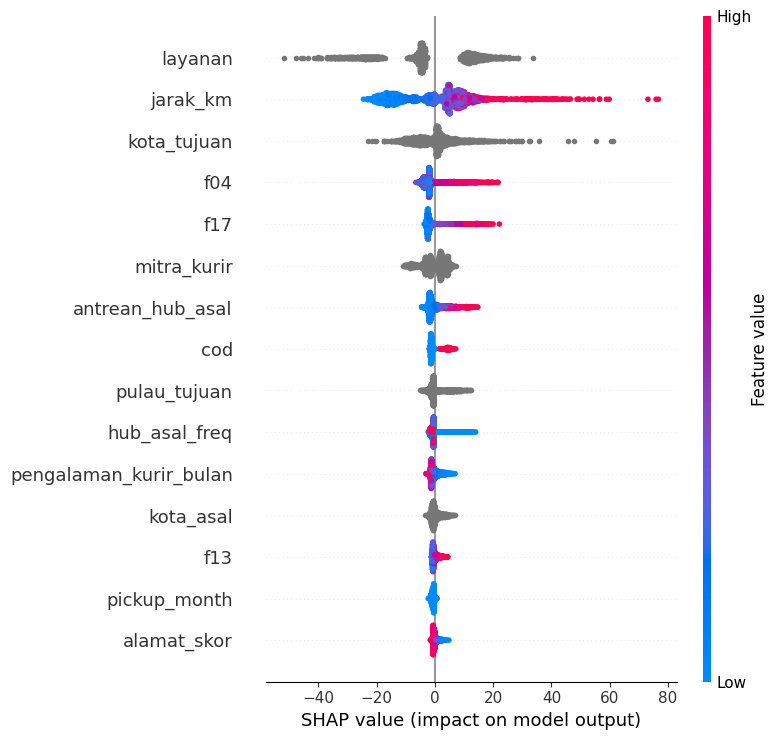

In [ ]:
import shap
import numpy as np
import pandas as pd

# 1. Error Breakdown per layanan, pulau_tujuan, dan mitra_kurir (pada Eval Set Agustus 2025 menggunakan model tuned)
eval_res = ev_prep[['layanan', 'pulau_tujuan', 'mitra_kurir']].copy()
eval_res['y_true'] = y_ev
eval_res['p50'] = p50_ev_final
eval_res['p90'] = p90_ev_final

def breakdown_metrics(df_grp, col):
    rows = []
    for k, g in df_grp.groupby(col, observed=True):
        rows.append({
            col: k,
            'count': len(g),
            'pinball_p50': pinball_loss(g['y_true'].values, g['p50'].values, 0.5),
            'pinball_p90': pinball_loss(g['y_true'].values, g['p90'].values, 0.9),
            'coverage_p90_%': np.mean(g['y_true'].values <= g['p90'].values) * 100
        })
    return pd.DataFrame(rows).sort_values('pinball_p50', ascending=False)

for seg_col in ['layanan', 'pulau_tujuan', 'mitra_kurir']:
    print(f"\n=== ERROR BREAKDOWN BY {seg_col.upper()} ===")
    print(breakdown_metrics(eval_res, seg_col).round(4).to_string(index=False))

# 2. Interpretabilitas Model dengan SHAP (pada model m50_tuned)
shap_sample = ev_prep[feat_cols].sample(n=min(2000, len(ev_prep)), random_state=42)
explainer = shap.TreeExplainer(m50_tuned)
shap_values = explainer.shap_values(shap_sample)

mean_abs_shap = pd.DataFrame({
    'fitur': feat_cols,
    'mean_abs_shap': np.abs(shap_values).mean(axis=0)
}).sort_values('mean_abs_shap', ascending=False)

print("\n=== TOP 15 FITUR PALING BERPENGARUH (SHAP P50) ===")
print(mean_abs_shap.head(15).round(4).to_string(index=False))

shap.summary_plot(shap_values, shap_sample, max_display=15, show=True)

## Pembuatan Script Python Reproduktibilitas Mandiri (`run_task1.py`)
Di bawah ini adalah sel yang menuliskan seluruh alur penyelesaian Task 1 ini ke dalam file `run_task1.py` agar penguji dapat mereplikasi seluruh metrik evaluasi dan prediksi akhir dengan satu baris perintah.

In [ ]:
script_code = g"""# -*- coding: utf-8 -*-
import os
import sys
import random
import numpy as np
import pandas as pd
import sklearn
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Setup & Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print("=== LIBRARY VERSIONS ===")
print(f"Python     : {sys.version.split()[0]}")
print(f"NumPy      : {np.__version__}")
print(f"Pandas     : {pd.__version__}")
print(f"Scikit-Learn: {sklearn.__version__}")
print(f"LightGBM   : {lgb.__version__}")

DRIVE_DATA = '/content/drive/MyDrive/matkul/PEMBELAJARAN MESIN(MACHINE LEARNING) BS1TK-47-REG-G05/data_uts_ML'
DATA_DIR = os.environ.get('UTS_DATA_DIR', DRIVE_DATA if os.path.exists(DRIVE_DATA) else 'data')

def load_dataset(base_name):
    gz_path = os.path.join(DATA_DIR, f'{base_name}.csv.gz')
    csv_path = os.path.join(DATA_DIR, f'{base_name}.csv')
    if os.path.exists(gz_path):
        return pd.read_csv(gz_path)
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'File {base_name}.csv(.gz) tidak ditemukan di {DATA_DIR}')

print("\nMemuat data...")
train_df = load_dataset('regresi_train')
test_df = load_dataset('regresi_test')

# 2. Preprocessing & Alignment functions
def prepare_features(df_in, route_medians=None, hub_medians=None, global_jarak_med=None, layanan_berat_med=None, freq_maps=None):
    d = df_in.copy()
    d['tgl_pickup'] = pd.to_datetime(d['tgl_pickup'])
    d['pickup_month'] = d['tgl_pickup'].dt.month
    d['pickup_dayofweek'] = d['tgl_pickup'].dt.dayofweek
    d['pickup_is_weekend'] = (d['pickup_dayofweek'] >= 5).astype(int)
    if 'jam_pickup' in d.columns:
        if d['jam_pickup'].dtype == 'object':
            d['jam_pickup_hour'] = pd.to_datetime(d['jam_pickup'], format='%H:%M:%S', errors='coerce').dt.hour.fillna(12)
        else:
            d['jam_pickup_hour'] = d['jam_pickup']
    d['is_jarak_invalid'] = d['jarak_km'].isin([0, 9999]).astype(int)
    d.loc[d['jarak_km'].isin([0, 9999]), 'jarak_km'] = np.nan
    d['is_berat_missing'] = d['berat_kg'].isna().astype(int)
    if route_medians is None:
        route_medians = d.groupby(['kota_asal', 'kota_tujuan'])['jarak_km'].median()
        hub_medians = d.groupby(['hub_asal', 'pulau_tujuan'])['jarak_km'].median()
        global_jarak_med = d['jarak_km'].median()
        layanan_berat_med = d.groupby('layanan')['berat_kg'].median()
    route_vals = pd.Series(d.set_index(['kota_asal', 'kota_tujuan']).index.map(route_medians).to_numpy(), index=d.index)
    hub_vals = pd.Series(d.set_index(['hub_asal', 'pulau_tujuan']).index.map(hub_medians).to_numpy(), index=d.index)
    d['jarak_km'] = d['jarak_km'].fillna(route_vals).fillna(hub_vals).fillna(global_jarak_med)
    d['berat_kg'] = d['berat_kg'].fillna(d['layanan'].map(layanan_berat_med)).fillna(layanan_berat_med.median())
    high_card_cols = ['kota_tujuan', 'kota_asal', 'mitra_kurir', 'hub_asal']
    if freq_maps is None:
        freq_maps = {col: d[col].value_counts(normalize=True).to_dict() for col in high_card_cols}
    for col in high_card_cols:
        d[f'{col}_freq'] = d[col].map(freq_maps[col]).fillna(0.0)
    return d, (route_medians, hub_medians, global_jarak_med, layanan_berat_med, freq_maps)

def align_categories(tr_df, other_dfs, cat_cols):
    tr_df = tr_df.copy()
    others = [d.copy() for d in other_dfs]
    for c in cat_cols:
        known = list(tr_df[c].astype(str).unique()) + ['__UNKNOWN__']
        dtype = pd.CategoricalDtype(categories=known, ordered=False)
        tr_df[c] = tr_df[c].astype(str).astype(dtype)
        for d in others:
            s = d[c].astype(str)
            d[c] = s.where(s.isin(known), '__UNKNOWN__').astype(dtype)
    return [tr_df] + others

def pinball_loss(y_true, y_pred, q):
    err = y_true - y_pred
    return np.mean(np.maximum(q * err, (q - 1) * err))

def evaluate_predictions(y_true, p50, p90, label=""):
    l50 = pinball_loss(y_true, p50, 0.5)
    l90 = pinball_loss(y_true, p90, 0.9)
    cov90 = np.mean(y_true <= p90) * 100
    print(f"[{label:32s}] Pinball P50={l50:.4f} | Pinball P90={l90:.4f} | P90 Coverage={cov90:.2f}%")
    return l50, l90, cov90

print("Processing fitur...")
cat_cols = ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
drop_cols = ['id_paket', 'tgl_pickup', 'jam_pickup', 'durasi_jam', 'jumlah_scan']

# Split waktu: Train, Cal, Eval
train_raw = train_df[train_df['tgl_pickup'] < '2025-07-01']
cal_raw   = train_df[(train_df['tgl_pickup'] >= '2025-07-01') & (train_df['tgl_pickup'] < '2025-08-01')]
eval_raw  = train_df[train_df['tgl_pickup'] >= '2025-08-01']

tr_prep, stats_pack = prepare_features(train_raw)
cal_prep, _ = prepare_features(cal_raw, *stats_pack)
ev_prep, _  = prepare_features(eval_raw, *stats_pack)
tr_prep, cal_prep, ev_prep = align_categories(tr_prep, [cal_prep, ev_prep], cat_cols)

feat_cols = [c for c in tr_prep.columns if c not in drop_cols]
num_cols = [c for c in feat_cols if c not in cat_cols]
y_tr, y_cal, y_ev = tr_prep['durasi_jam'].values, cal_prep['durasi_jam'].values, ev_prep['durasi_jam'].values

# --- 3. Evaluasi Semua Model pada Set Agustus 2025 ---
print("\n=== REPRODUCE ALL REPORT METRICS (Agustus 2025) ===")

# 3.0 Baseline
base_p50_map = tr_prep.groupby('layanan')['durasi_jam'].quantile(0.5).to_dict()
base_p90_map = tr_prep.groupby('layanan')['durasi_jam'].quantile(0.9).to_dict()
p50_base = ev_prep['layanan'].map(base_p50_map).values
p90_base = ev_prep['layanan'].map(base_p90_map).values
evaluate_predictions(y_ev, p50_base, p90_base, "0. Baseline (Per Layanan)")

# 3.1 Ridge
pre_linear = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), cat_cols)
])
ridge_pipe = Pipeline([('pre', pre_linear), ('model', Ridge(alpha=10.0, random_state=SEED))])
ridge_pipe.fit(tr_prep[feat_cols], np.log1p(y_tr))
log_pred_cal = ridge_pipe.predict(cal_prep[feat_cols])
res_log_cal = np.log1p(y_cal) - log_pred_cal
q90_res_log = np.quantile(res_log_cal, 0.90)
log_pred_ev = ridge_pipe.predict(ev_prep[feat_cols])
p50_ridge = np.expm1(log_pred_ev)
p90_ridge = np.maximum(p50_ridge, np.expm1(log_pred_ev + q90_res_log))
evaluate_predictions(y_ev, p50_ridge, p90_ridge, "1. Ridge (log1p + Residual Q90)")

# 3.2 LightGBM Untuned
for dset in [tr_prep, cal_prep, ev_prep]:
    for c in cat_cols:
        dset[c] = dset[c].astype('category')
lgb50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=SEED, verbose=-1)
lgb90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=SEED, verbose=-1)
lgb50.fit(tr_prep[feat_cols], y_tr)
lgb90.fit(tr_prep[feat_cols], y_tr)
p50_lgb_cal = lgb50.predict(cal_prep[feat_cols])
p90_lgb_cal = np.maximum(p50_lgb_cal, lgb90.predict(cal_prep[feat_cols]))
p50_lgb_ev = lgb50.predict(ev_prep[feat_cols])
p90_lgb_ev = np.maximum(p50_lgb_ev, lgb90.predict(ev_prep[feat_cols]))
cal_errors = y_cal - p90_lgb_cal
delta_90 = np.quantile(cal_errors, 0.90)
p90_lgb_cqr = np.maximum(p50_lgb_ev, p90_lgb_ev + delta_90)
evaluate_predictions(y_ev, p50_lgb_ev, p90_lgb_cqr, "2. LightGBM Untuned + CQR")

# 3.3 Tuned LightGBM + CQR
params_p50 = {'num_leaves': 127, 'learning_rate': 0.03, 'min_child_samples': 100, 'n_estimators': 700}
params_p90 = {'num_leaves': 31,  'learning_rate': 0.05, 'min_child_samples': 50,  'n_estimators': 400}
m50_tuned = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=SEED, verbose=-1, **params_p50)
m90_tuned = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=SEED, verbose=-1, **params_p90)
m50_tuned.fit(tr_prep[feat_cols], y_tr)
m90_tuned.fit(tr_prep[feat_cols], y_tr)
p50_cal = m50_tuned.predict(cal_prep[feat_cols])
p90_cal = np.maximum(p50_cal, m90_tuned.predict(cal_prep[feat_cols]))
delta_90_final = np.quantile(y_cal - p90_cal, 0.90)
p50_ev_final = m50_tuned.predict(ev_prep[feat_cols])
p90_ev_final = np.maximum(p50_ev_final, m90_tuned.predict(ev_prep[feat_cols]) + delta_90_final)
evaluate_predictions(y_ev, p50_ev_final, p90_ev_final, "3. Tuned LightGBM + CQR (Final)")

# 4. Error Breakdown
print("\n=== ERROR BREAKDOWN BY SEGMENT (Tuned Model) ===")
eval_res = ev_prep[['layanan', 'pulau_tujuan', 'mitra_kurir']].copy()
eval_res['y_true'] = y_ev
eval_res['p50'] = p50_ev_final
eval_res['p90'] = p90_ev_final

def breakdown_metrics(df_grp, col):
    rows = []
    for k, g in df_grp.groupby(col, observed=True):
        rows.append({
            col: k,
            'count': len(g),
            'pinball_p50': pinball_loss(g['y_true'].values, g['p50'].values, 0.5),
            'pinball_p90': pinball_loss(g['y_true'].values, g['p90'].values, 0.9),
            'coverage_p90_%': np.mean(g['y_true'].values <= g['p90'].values) * 100
        })
    return pd.DataFrame(rows).sort_values('pinball_p50', ascending=False)

for seg_col in ['layanan', 'pulau_tujuan', 'mitra_kurir']:
    print(f"\n=== {seg_col.upper()} ===")
    print(breakdown_metrics(eval_res, seg_col).round(4).to_string(index=False))

# 5. Retrain on Full Dataset and Predict Test
print("\nMelakukan final training di seluruh data train...")
full_tr_prep, full_stats_pack = prepare_features(train_df)
full_ts_prep, _ = prepare_features(test_df, *full_stats_pack)
full_tr_prep, full_ts_prep = align_categories(full_tr_prep, [full_ts_prep], cat_cols)

lgb50_final = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=SEED, verbose=-1, **params_p50)
lgb90_final = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=SEED, verbose=-1, **params_p90)
lgb50_final.fit(full_tr_prep[feat_cols], full_tr_prep['durasi_jam'].values)
lgb90_final.fit(full_tr_prep[feat_cols], full_tr_prep['durasi_jam'].values)

p50_test = lgb50_final.predict(full_ts_prep[feat_cols])
p90_test = np.maximum(p50_test, lgb90_final.predict(full_ts_prep[feat_cols]) + delta_90_final)

sub_regresi = pd.DataFrame({
    'id_paket': test_df['id_paket'],
    'p50': np.round(p50_test, 4),
    'p90': np.round(p90_test, 4)
})

assert list(sub_regresi.columns) == ['id_paket', 'p50', 'p90']
assert len(sub_regresi) == len(test_df)
assert not sub_regresi.isna().any().any()
assert (sub_regresi['p90'] >= sub_regresi['p50']).all()

sub_regresi.to_csv('prediksi_regresi.csv', index=False)
print("prediksi_regresi.csv berhasil disimpan! Shape:", sub_regresi.shape)
"""

with open('run_task1.py', 'w', encoding='utf-8') as f:
    f.write(script_code)

print("File run_task1.py berhasil diekspor!")

File run_task1.py berhasil diekspor!


In [ ]:
from google.colab import files
files.download('prediksi_regresi.csv')

In [ ]:
!python run_task1.py

=== LIBRARY VERSIONS ===
Python     : 3.13.18
NumPy      : 2.4.6
Pandas     : 2.2.3
Scikit-Learn: 1.6.1
LightGBM   : 4.6.0

Memuat data...
Processing fitur...

=== REPRODUCE ALL REPORT METRICS (Agustus 2025) ===
/content/run_task1.py:120: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  base_p50_map = tr_prep.groupby('layanan')['durasi_jam'].quantile(0.5).to_dict()
/content/run_task1.py:121: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  base_p90_map = tr_prep.groupby('layanan')['durasi_jam'].quantile(0.9).to_dict()
[0. Baseline (Per Layanan)       ] Pinball P50=15.8670 | Pinball P90=15.1018 | P90 Coverage=89.55%